# Лабораторная работа 8. Классификация изображений (классические методы работы с изображениями)

In [1]:
%pip install scikit-image

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os 
import numpy as np 
import pandas as pd

from skimage.feature import hog 
from skimage.io import imread, imshow
from skimage.transform import resize
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_curve, roc_auc_score, confusion_matrix

from sklearn.neighbors import KNeighborsClassifier

## Датасет: есть кошка / нет кошки

Собрана выборка из 200 фотографий: 100 кошек (метка 1) и 100 собак (метка 0). Собаки выбраны как тематически близкий отрицательный класс.

Источник: [Cats and Dogs, учебный пример TensorFlow](https://www.tensorflow.org/tutorials/images/transfer_learning)

In [3]:
from pathlib import Path

# Объект распознавания — кошка. Отрицательный класс — собаки
data_dir = Path('lab_08_data') / 'cats_vs_dogs'
cats_dir = data_dir / 'cats'
dogs_dir = data_dir / 'dogs'

for folder in [cats_dir, dogs_dir]:
    if not folder.is_dir():
        raise FileNotFoundError(f'Не найдена папка: {folder.resolve()}')


In [4]:
X = []
y = []
filenames = []

for folder, label in [(cats_dir, 1), (dogs_dir, 0)]:
    files = sorted(p for p in folder.iterdir()
                   if p.suffix.lower() in ('.jpg', '.jpeg', '.png'))
    for path in files:
        image = imread(path)
        X.append(image)
        y.append(label)
        filenames.append(path.relative_to(data_dir).as_posix())

y = np.array(y)
filenames = np.array(filenames)

print('Всего изображений:', len(X))
print('Кошек (класс 1):', np.sum(y == 1))
print('Собак (класс 0):', np.sum(y == 0))

assert len(X) == 200
assert np.sum(y == 1) == 100 and np.sum(y == 0) == 100


Всего изображений: 200
Кошек (класс 1): 100
Собак (класс 0): 100


In [5]:
X_resized = []

for image in X:
    resized = resize(image, (100, 100), anti_aliasing=True)
    X_resized.append(resized)

X_resized = np.array(X_resized)

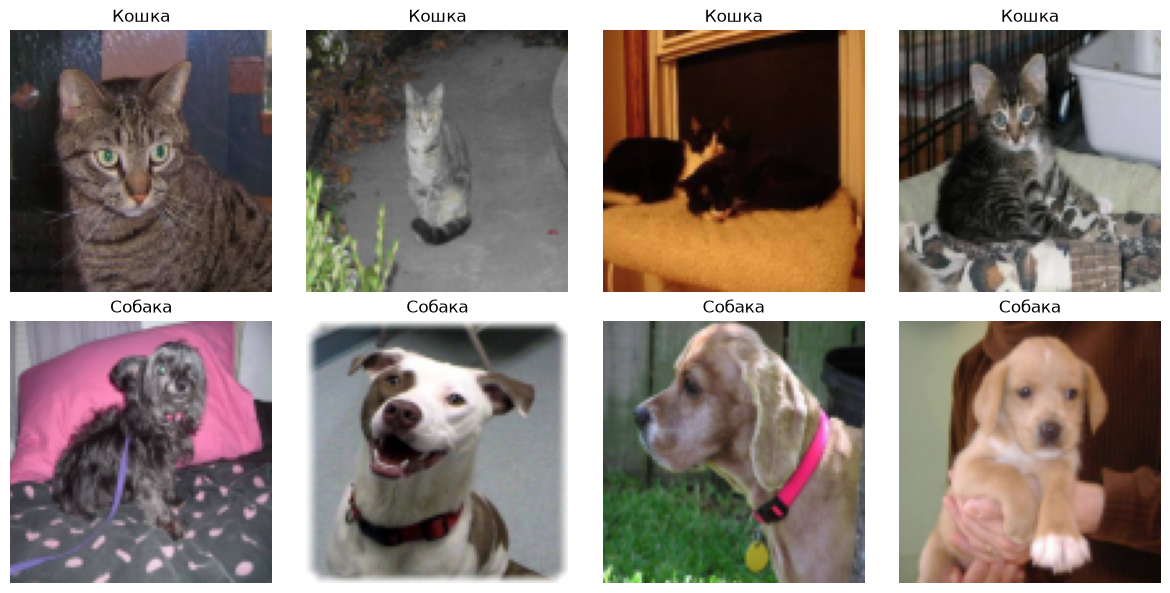

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

indices = [0, 1, 2, 3, 100, 101, 102, 103]

for i, ax in zip(indices, axes.flat):
    ax.imshow(X_resized[i])
    ax.axis('off')
    ax.set_title('Кошка' if y[i] == 1 else 'Собака')

plt.tight_layout()
plt.show()

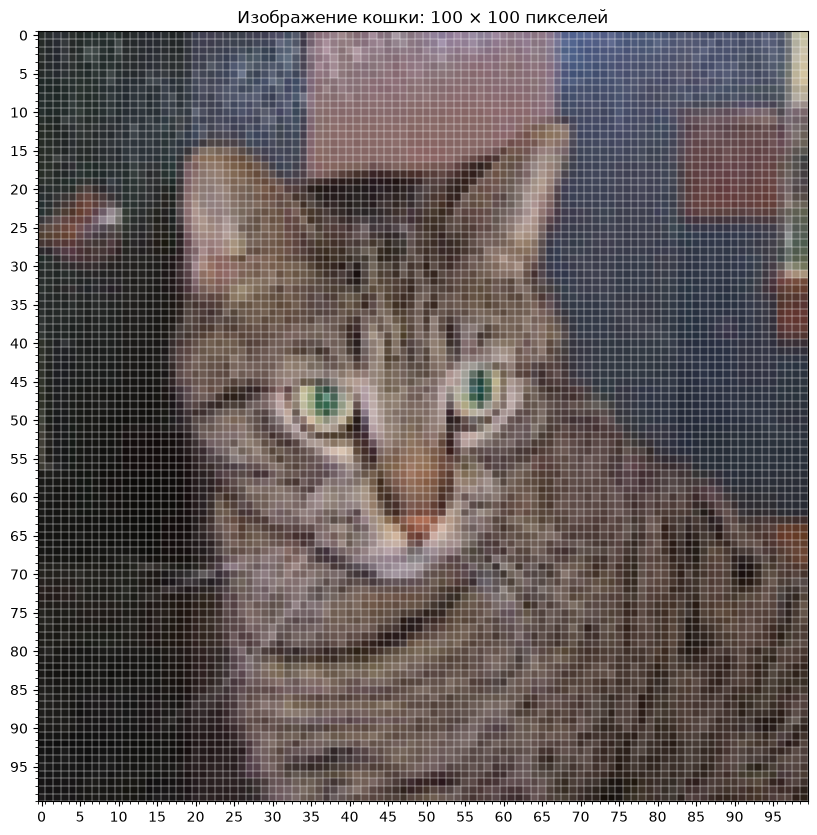

In [7]:
fig, ax = plt.subplots(figsize=(10,10))

ax.imshow(X_resized[0])

ax.set_xticks(np.arange(0, 100, 5))
ax.set_yticks(np.arange(0, 100, 5))

ax.set_xticks(np.arange(-0.5, 100, 1), minor = True)
ax.set_yticks(np.arange(-0.5, 100, 1), minor = True)

ax.grid(which = 'minor', color='white', linestyle='-', linewidth=0.3)

ax.set_title('Изображение кошки: 100 × 100 пикселей')

plt.show()

In [8]:
print('Размер изображения:', X_resized[0].shape)

print('\nЗначение пикселя (10, 20):')
print(X_resized[0][10, 20])

Размер изображения: (100, 100, 3)

Значение пикселя (10, 20):
[0.36434859 0.38685532 0.44965305]


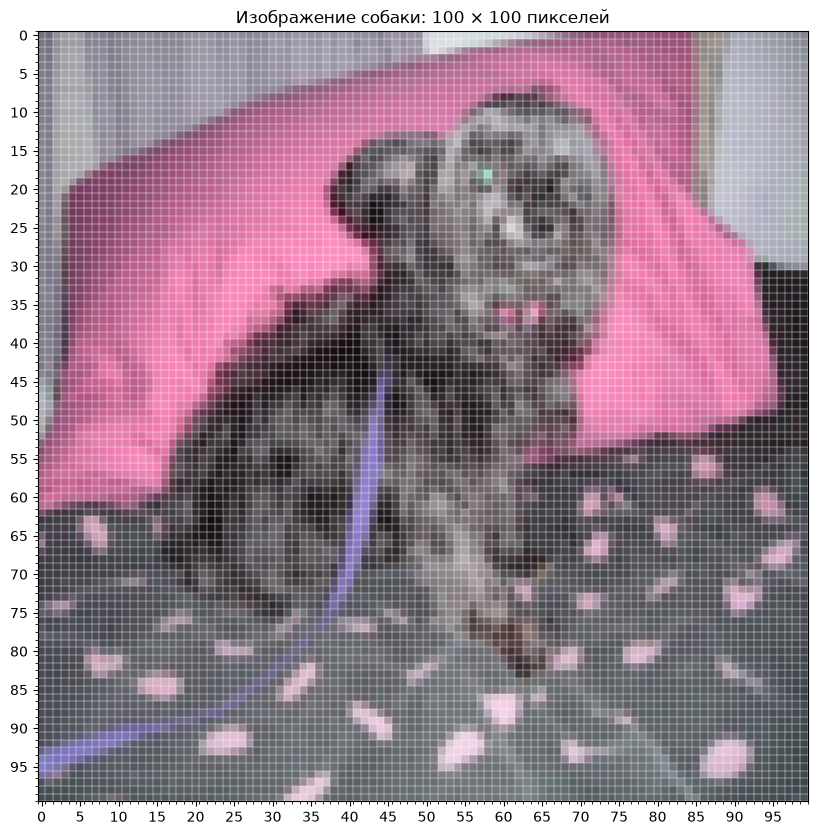

In [9]:
fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(X_resized[100])

ax.set_xticks(np.arange(0, 100, 5))
ax.set_yticks(np.arange(0, 100, 5))

ax.set_xticks(np.arange(-0.5, 100, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 100, 1), minor=True)

ax.grid(which='minor', color='white', linestyle='-', linewidth=0.3)

ax.set_title('Изображение собаки: 100 × 100 пикселей')

plt.show()

In [10]:
print('Размер изображения:', X_resized[100].shape)

print('\nЗначение пикселя (10, 20):')
print(X_resized[100][10, 20])

Размер изображения: (100, 100, 3)

Значение пикселя (10, 20):
[0.62241418 0.58898081 0.64881667]


In [11]:
X_hog = []
y_hog = []

for image, label in zip(X_resized, y): 
    gray = np.dot(image[...,:3], [0.2125, 0.7154, 0.0721])

    features = hog(
        gray, 
        orientations = 9, 
        pixels_per_cell = (8, 8),
        cells_per_block=(2,2),
        block_norm='L2',
        feature_vector = True
    )

    X_hog.append(features)
    y_hog.append(label)

X_hog = np.array(X_hog)
y_hog = np.array(y_hog)

print('Размер матрицы признаков:', X_hog.shape)
print('Размер вектора классов:', y_hog.shape)

Размер матрицы признаков: (200, 4356)
Размер вектора классов: (200,)


In [12]:
print('Количество изображений с кошками:', np.sum(y_hog == 0))
print('Количество изображений с собаками:', np.sum(y_hog == 1))

Количество изображений с кошками: 100
Количество изображений с собаками: 100


In [13]:
indices = np.arange(len(y_hog))

train_idx, test_idx, y_train, y_test = train_test_split(
    indices, 
    y_hog, 
    test_size = 0.2, 
    random_state = 42, 
    stratify=y_hog
)

X_train = X_hog[train_idx]
X_test = X_hog[test_idx]

print('Обучающая выборка:' ,X_train.shape)
print('Тестовая выборка:' ,X_test.shape)

Обучающая выборка: (160, 4356)
Тестовая выборка: (40, 4356)


In [14]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

svm_model = Pipeline([
    ('scaler', StandardScaler()), 
    ('svm', SVC(kernel='rbf', C=1, gamma = 'scale'))
])

svm_model = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1, gamma='scale'))
])

svm_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4356
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [15]:
y_pred = svm_model.predict(X_test)


In [16]:
from sklearn.metrics import accuracy_score, classification_report

print('Accuracy: ', accuracy_score(y_test, y_pred))

print('\nClassification report:')
print(classification_report(
    y_test,
    y_pred,
    target_names=['Кошка', 'Собака']
))

Accuracy:  0.775

Classification report:
              precision    recall  f1-score   support

       Кошка       0.79      0.75      0.77        20
      Собака       0.76      0.80      0.78        20

    accuracy                           0.78        40
   macro avg       0.78      0.78      0.77        40
weighted avg       0.78      0.78      0.77        40



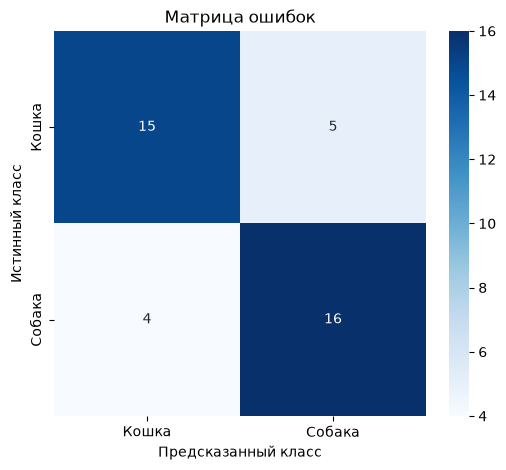

In [17]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Кошка', 'Собака'],
    yticklabels=['Кошка', 'Собака']
)

plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.title('Матрица ошибок')
plt.show()

In [18]:
errors = np.where(y_test != y_pred)[0]

print('Количество ошибок:', len(errors))
print('Индексы ошибочных изображений в тестовой выборке:', errors)

Количество ошибок: 9
Индексы ошибочных изображений в тестовой выборке: [ 3 14 19 20 24 25 32 37 39]


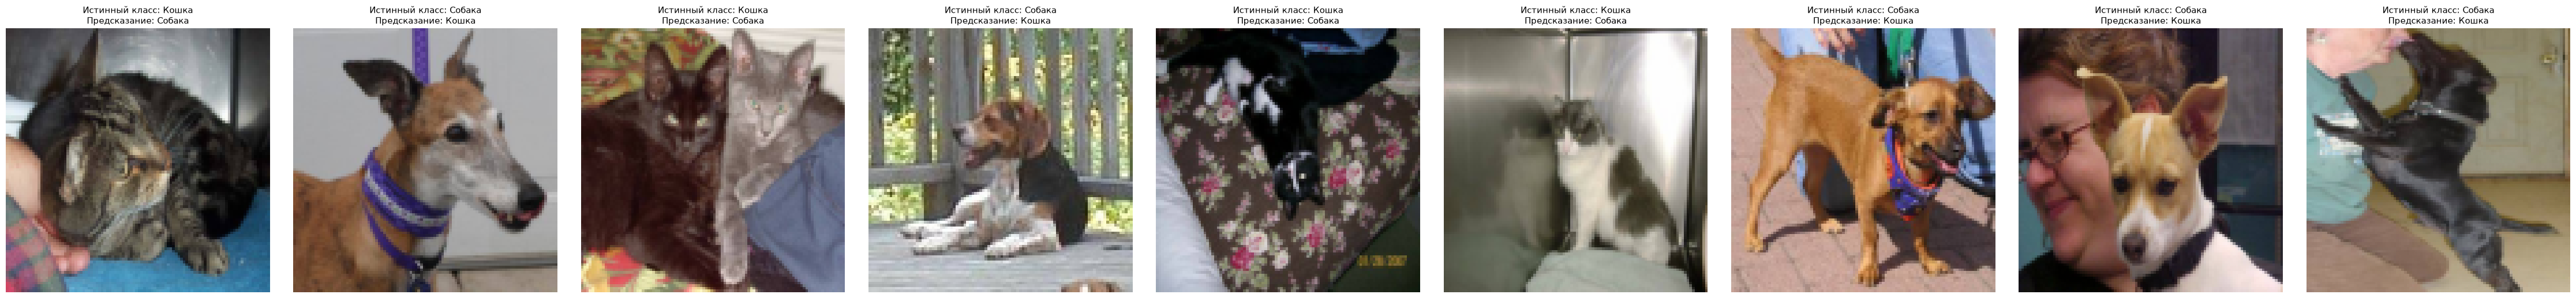

In [19]:
fig, axes = plt.subplots(
    1, len(errors),
    figsize=(5 * len(errors), 5)
)

if len(errors) == 1:
    axes = [axes]

for ax, error_idx in zip(axes, errors):

    # Получаем индекс изображения в исходном датасете
    original_idx = test_idx[error_idx]

    # Истинный и предсказанный классы
    true_label = 'Кошка' if y_test[error_idx] == 1 else 'Собака'
    pred_label = 'Кошка' if y_pred[error_idx] == 1 else 'Собака'

    ax.imshow(X_resized[original_idx])
    ax.set_title(
        f'Истинный класс: {true_label}\n'
        f'Предсказание: {pred_label}',
        fontsize=11
    )
    ax.axis('off')

plt.tight_layout()
plt.show()